In [ ]:
!pip install git+https://github.com/tensorflow/docs

  Cloning https://github.com/tensorflow/docs to /tmp/pip-req-build-9woxgtfm
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs /tmp/pip-req-build-9woxgtfm
  Resolved https://github.com/tensorflow/docs to commit 0054afff57cd4a4ea5389088a89942603461ee6f
  Preparing metadata (setup.py) ... done
  Created wheel for tensorflow-docs: filename=tensorflow_docs-2026.5.12.61975-py3-none-any.whl size=186932 sha256=4750c12a4e4c940229f412fe0ec85690597a1a7f6c042aa6c5e25de0aa71c00b
  Stored in directory: /tmp/pip-ephem-wheel-cache-dlkoewcn/wheels/3e/88/34/48d2789bc9d37b33ddce06bccc454fae0285e5396d0a5be9d9
Successfully built tensorflow-docs


In [ ]:
import tensorflow as tf
import os
import random
import numpy as np

GLOBAL_SEED = 42

os.environ['PYTHONHASHSEED'] = str(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
tf.random.set_seed(GLOBAL_SEED)

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 28*28).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 28*28).astype("float32") / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Epoch 1/20
1688/1688 - 10s - 6ms/step - accuracy: 0.9306 - loss: 0.2360 - pure_loss: 0.2359 - val_accuracy: 0.9680 - val_loss: 0.1098 - val_pure_loss: 0.1096
Epoch 2/20
1688/1688 - 4s - 3ms/step - accuracy: 0.9709 - loss: 0.0955 - pure_loss: 0.0955 - val_accuracy: 0.9707 - val_loss: 0.0934 - val_pure_loss: 0.0932
Epoch 3/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9820 - loss: 0.0613 - pure_loss: 0.0613 - val_accuracy: 0.9720 - val_loss: 0.0889 - val_pure_loss: 0.0887
Epoch 4/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9883 - loss: 0.0413 - pure_loss: 0.0413 - val_accuracy: 0.9752 - val_loss: 0.0849 - val_pure_loss: 0.0846
Epoch 5/20
1688/1688 - 4s - 3ms/step - accuracy: 0.9922 - loss: 0.0281 - pure_loss: 0.0281 - val_accuracy: 0.9780 - val_loss: 0.0816 - val_pure_loss: 0.0814
Epoch 6/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9945 - loss: 0.0203 - pure_loss: 0.0203 - val_accuracy: 0.9763 - val_loss: 0.0979 - val_pure_loss: 0.0976
Epoch 7/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9956 -

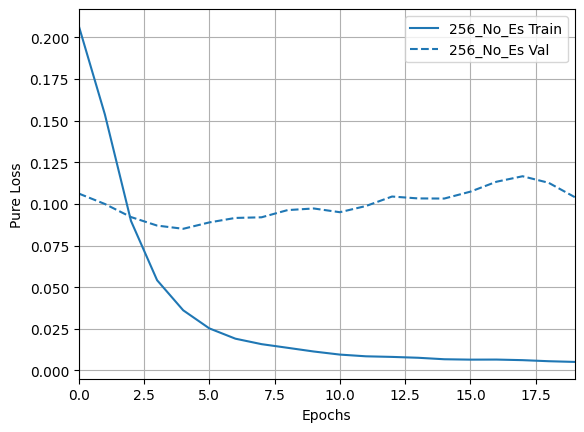

In [ ]:

import matplotlib.pyplot as plt
import tensorflow_docs as tfdocs
import tensorflow_docs.modeling
import tensorflow_docs.plots

histories = {}

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_no_es = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_256_no_es.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_no_es = model_256_no_es.fit(
    x_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=2
)
histories['256_no_es'] = histories_256_no_es

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)


Epoch 1/20
1688/1688 - 8s - 5ms/step - accuracy: 0.9308 - loss: 0.2375 - pure_loss: 0.2374 - val_accuracy: 0.9682 - val_loss: 0.1091 - val_pure_loss: 0.1089
Epoch 2/20
1688/1688 - 4s - 3ms/step - accuracy: 0.9708 - loss: 0.0979 - pure_loss: 0.0979 - val_accuracy: 0.9728 - val_loss: 0.0905 - val_pure_loss: 0.0903
Epoch 3/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9811 - loss: 0.0636 - pure_loss: 0.0636 - val_accuracy: 0.9747 - val_loss: 0.0862 - val_pure_loss: 0.0860
Epoch 4/20
1688/1688 - 4s - 3ms/step - accuracy: 0.9874 - loss: 0.0431 - pure_loss: 0.0431 - val_accuracy: 0.9763 - val_loss: 0.0884 - val_pure_loss: 0.0882
Epoch 5/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9920 - loss: 0.0296 - pure_loss: 0.0296 - val_accuracy: 0.9747 - val_loss: 0.0966 - val_pure_loss: 0.0963
Epoch 6/20
1688/1688 - 5s - 3ms/step - accuracy: 0.9935 - loss: 0.0219 - pure_loss: 0.0218 - val_accuracy: 0.9765 - val_loss: 0.0982 - val_pure_loss: 0.0979
Epoch 7/20
1688/1688 - 4s - 3ms/step - accuracy: 0.9944 - 

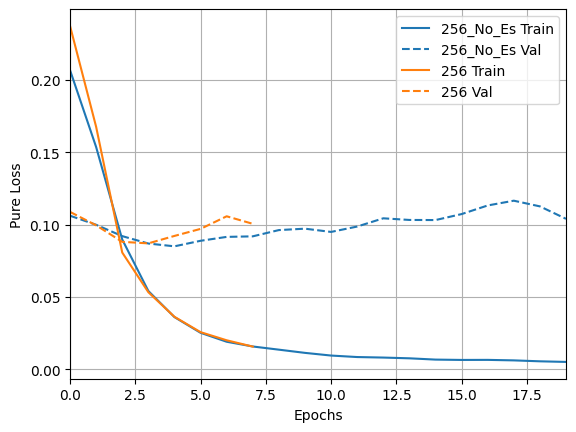

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_256.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256 = model_256.fit(
    x_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)
histories['256'] = histories_256

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

In [ ]:
import numpy as np

ids = np.random.choice(len(x_train), 3000, replace=False)
x_train_short = x_train[ids]
y_train_short = y_train[ids]

Epoch 1/50
85/85 - 3s - 36ms/step - accuracy: 0.7437 - loss: 0.8573 - pure_loss: 0.8544 - val_accuracy: 0.9033 - val_loss: 0.3897 - val_pure_loss: 0.3836
Epoch 2/50
85/85 - 0s - 4ms/step - accuracy: 0.8996 - loss: 0.3464 - pure_loss: 0.3450 - val_accuracy: 0.9300 - val_loss: 0.2918 - val_pure_loss: 0.2837
Epoch 3/50
85/85 - 0s - 4ms/step - accuracy: 0.9337 - loss: 0.2420 - pure_loss: 0.2409 - val_accuracy: 0.9433 - val_loss: 0.2501 - val_pure_loss: 0.2415
Epoch 4/50
85/85 - 0s - 4ms/step - accuracy: 0.9589 - loss: 0.1767 - pure_loss: 0.1759 - val_accuracy: 0.9400 - val_loss: 0.2282 - val_pure_loss: 0.2191
Epoch 5/50
85/85 - 0s - 4ms/step - accuracy: 0.9722 - loss: 0.1327 - pure_loss: 0.1321 - val_accuracy: 0.9433 - val_loss: 0.2110 - val_pure_loss: 0.2018
Epoch 6/50
85/85 - 0s - 3ms/step - accuracy: 0.9796 - loss: 0.1008 - pure_loss: 0.1004 - val_accuracy: 0.9433 - val_loss: 0.2032 - val_pure_loss: 0.1939
Epoch 7/50
85/85 - 0s - 4ms/step - accuracy: 0.9867 - loss: 0.0772 - pure_loss: 0

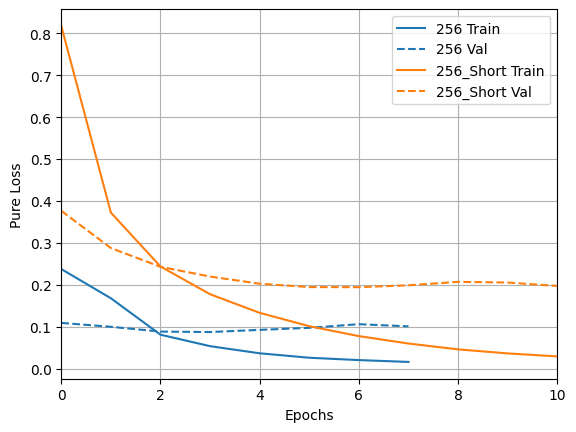

In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_short = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_256_short.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_short = model_256_short.fit(
    x_train_short, y_train_short,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)
histories['256_short'] = histories_256_short

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

Epoch 1/50
1688/1688 - 8s - 5ms/step - accuracy: 0.9439 - loss: 0.1837 - pure_loss: 0.1837 - val_accuracy: 0.9710 - val_loss: 0.0912 - val_pure_loss: 0.0910
Epoch 2/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9777 - loss: 0.0726 - pure_loss: 0.0726 - val_accuracy: 0.9722 - val_loss: 0.0946 - val_pure_loss: 0.0945
Epoch 3/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9867 - loss: 0.0436 - pure_loss: 0.0436 - val_accuracy: 0.9740 - val_loss: 0.0940 - val_pure_loss: 0.0938
Epoch 4/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9899 - loss: 0.0315 - pure_loss: 0.0315 - val_accuracy: 0.9755 - val_loss: 0.1000 - val_pure_loss: 0.0997
Epoch 5/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9914 - loss: 0.0269 - pure_loss: 0.0269 - val_accuracy: 0.9800 - val_loss: 0.1020 - val_pure_loss: 0.1017
Epoch 6/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9934 - loss: 0.0213 - pure_loss: 0.0213 - val_accuracy: 0.9797 - val_loss: 0.0978 - val_pure_loss: 0.0975
Epoch 6: early stopping
Restoring model weights from the e

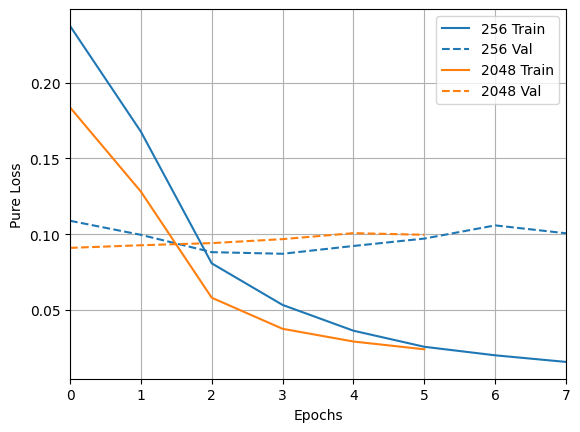

In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_2048 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(2048, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_2048.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_2048 = model_2048.fit(
    x_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)
histories['2048'] = histories_2048

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

Epoch 1/50
1688/1688 - 10s - 6ms/step - accuracy: 0.9261 - loss: 0.2472 - pure_loss: 0.2471 - val_accuracy: 0.9683 - val_loss: 0.1117 - val_pure_loss: 0.1114
Epoch 2/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9695 - loss: 0.1017 - pure_loss: 0.1016 - val_accuracy: 0.9680 - val_loss: 0.1097 - val_pure_loss: 0.1095
Epoch 3/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9791 - loss: 0.0692 - pure_loss: 0.0692 - val_accuracy: 0.9722 - val_loss: 0.0912 - val_pure_loss: 0.0909
Epoch 4/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9836 - loss: 0.0520 - pure_loss: 0.0520 - val_accuracy: 0.9753 - val_loss: 0.0942 - val_pure_loss: 0.0939
Epoch 5/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9872 - loss: 0.0422 - pure_loss: 0.0422 - val_accuracy: 0.9772 - val_loss: 0.0957 - val_pure_loss: 0.0955
Epoch 6/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9890 - loss: 0.0347 - pure_loss: 0.0347 - val_accuracy: 0.9732 - val_loss: 0.1073 - val_pure_loss: 0.1071
Epoch 7/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9902 -

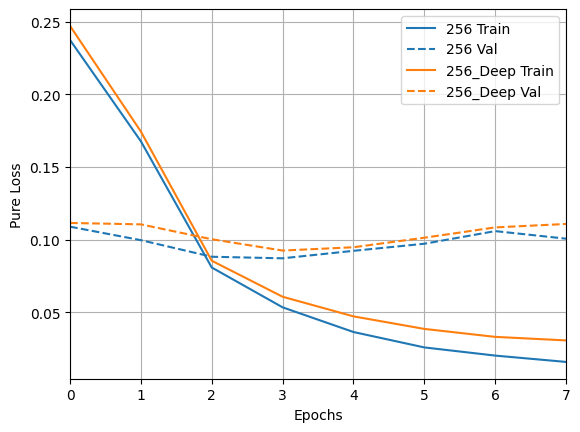

In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_deep = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_256_deep.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_deep = model_256_deep.fit(
    x_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)
histories['256_deep'] = histories_256_deep

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

Epoch 1/50
1688/1688 - 11s - 6ms/step - accuracy: 0.9361 - loss: 0.2122 - pure_loss: 0.2121 - val_accuracy: 0.9745 - val_loss: 0.0885 - val_pure_loss: 0.0883
Epoch 2/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9707 - loss: 0.0983 - pure_loss: 0.0983 - val_accuracy: 0.9682 - val_loss: 0.1126 - val_pure_loss: 0.1123
Epoch 3/50
1688/1688 - 6s - 3ms/step - accuracy: 0.9791 - loss: 0.0681 - pure_loss: 0.0681 - val_accuracy: 0.9757 - val_loss: 0.0893 - val_pure_loss: 0.0890
Epoch 4/50
1688/1688 - 6s - 3ms/step - accuracy: 0.9847 - loss: 0.0509 - pure_loss: 0.0509 - val_accuracy: 0.9715 - val_loss: 0.1081 - val_pure_loss: 0.1078
Epoch 5/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9871 - loss: 0.0438 - pure_loss: 0.0438 - val_accuracy: 0.9738 - val_loss: 0.1020 - val_pure_loss: 0.1017
Epoch 6/50
1688/1688 - 6s - 4ms/step - accuracy: 0.9887 - loss: 0.0360 - pure_loss: 0.0360 - val_accuracy: 0.9810 - val_loss: 0.0812 - val_pure_loss: 0.0810
Epoch 7/50
1688/1688 - 5s - 3ms/step - accuracy: 0.9907 -

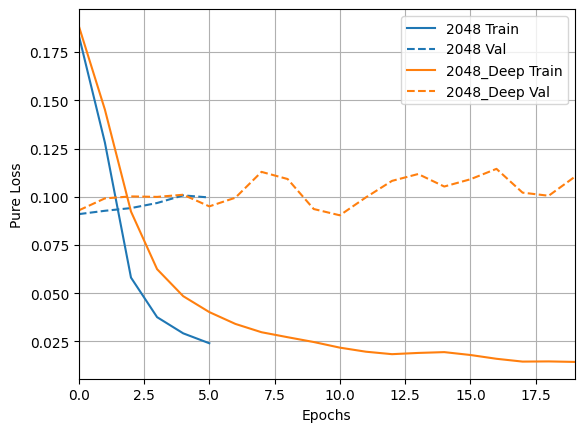

In [ ]:
histories = {}
histories['2048'] = histories_2048

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_2048_deep = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(2048, activation="relu"),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_2048_deep.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_2048_deep = model_2048_deep.fit(
    x_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)
histories['2048_deep'] = histories_2048_deep

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_l1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l1(0.0001)
      ),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1),
]

model_256_l1.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_l1 = model_256_l1.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

histories['256_l1'] = histories_256_l1

Epoch 1/200
1688/1688 - 8s - 5ms/step - accuracy: 0.9233 - loss: 0.5398 - pure_loss: 0.2706 - val_accuracy: 0.9642 - val_loss: 0.3280 - val_pure_loss: 0.1375
Epoch 2/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9584 - loss: 0.3196 - pure_loss: 0.1460 - val_accuracy: 0.9715 - val_loss: 0.2713 - val_pure_loss: 0.1090
Epoch 3/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9671 - loss: 0.2687 - pure_loss: 0.1147 - val_accuracy: 0.9747 - val_loss: 0.2441 - val_pure_loss: 0.0962
Epoch 4/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9724 - loss: 0.2380 - pure_loss: 0.0977 - val_accuracy: 0.9752 - val_loss: 0.2197 - val_pure_loss: 0.0852
Epoch 5/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9751 - loss: 0.2177 - pure_loss: 0.0877 - val_accuracy: 0.9755 - val_loss: 0.2102 - val_pure_loss: 0.0837
Epoch 6/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9766 - loss: 0.2030 - pure_loss: 0.0800 - val_accuracy: 0.9755 - val_loss: 0.2007 - val_pure_loss: 0.0806
Epoch 7/200
1688/1688 - 5s - 3ms/step - accuracy: 0.

Epoch 1/200
1688/1688 - 8s - 5ms/step - accuracy: 0.9302 - loss: 0.2732 - pure_loss: 0.2401 - val_accuracy: 0.9683 - val_loss: 0.1440 - val_pure_loss: 0.1074
Epoch 2/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9686 - loss: 0.1443 - pure_loss: 0.1059 - val_accuracy: 0.9730 - val_loss: 0.1303 - val_pure_loss: 0.0899
Epoch 3/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9779 - loss: 0.1166 - pure_loss: 0.0751 - val_accuracy: 0.9750 - val_loss: 0.1272 - val_pure_loss: 0.0844
Epoch 4/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9832 - loss: 0.1018 - pure_loss: 0.0586 - val_accuracy: 0.9765 - val_loss: 0.1258 - val_pure_loss: 0.0817
Epoch 5/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9866 - loss: 0.0922 - pure_loss: 0.0480 - val_accuracy: 0.9765 - val_loss: 0.1236 - val_pure_loss: 0.0790
Epoch 6/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9881 - loss: 0.0862 - pure_loss: 0.0415 - val_accuracy: 0.9748 - val_loss: 0.1273 - val_pure_loss: 0.0821
Epoch 7/200
1688/1688 - 4s - 3ms/step - accuracy: 0.

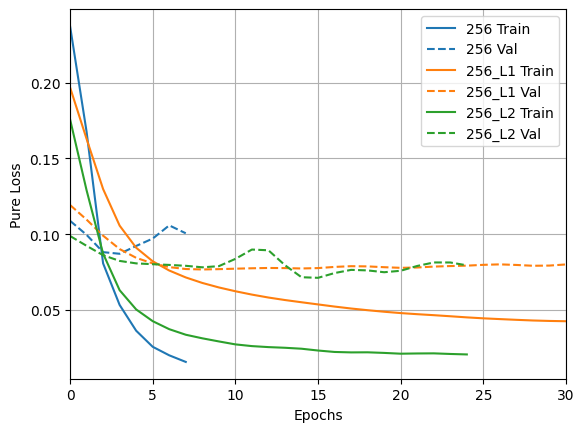

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_l2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
      ),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1),
]

model_256_l2.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_l2 = model_256_l2.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

histories['256_l2'] = histories_256_l2

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)


In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_drop_02 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=5, restore_best_weights=True, verbose=1),
]

model_256_drop_02.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_drop_02 = model_256_drop_02.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

histories['256_drop_02'] = histories_256_drop_02

Epoch 1/200
1688/1688 - 8s - 5ms/step - accuracy: 0.9231 - loss: 0.2638 - pure_loss: 0.2638 - val_accuracy: 0.9698 - val_loss: 0.1055 - val_pure_loss: 0.1052
Epoch 2/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9639 - loss: 0.1194 - pure_loss: 0.1194 - val_accuracy: 0.9737 - val_loss: 0.0853 - val_pure_loss: 0.0851
Epoch 3/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9739 - loss: 0.0868 - pure_loss: 0.0868 - val_accuracy: 0.9770 - val_loss: 0.0784 - val_pure_loss: 0.0782
Epoch 4/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9797 - loss: 0.0661 - pure_loss: 0.0661 - val_accuracy: 0.9793 - val_loss: 0.0735 - val_pure_loss: 0.0733
Epoch 5/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9826 - loss: 0.0535 - pure_loss: 0.0535 - val_accuracy: 0.9758 - val_loss: 0.0844 - val_pure_loss: 0.0842
Epoch 6/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9851 - loss: 0.0445 - pure_loss: 0.0444 - val_accuracy: 0.9798 - val_loss: 0.0760 - val_pure_loss: 0.0758
Epoch 7/200
1688/1688 - 5s - 3ms/step - accuracy: 0.

Epoch 1/200
1688/1688 - 9s - 5ms/step - accuracy: 0.8993 - loss: 0.3367 - pure_loss: 0.3366 - val_accuracy: 0.9665 - val_loss: 0.1217 - val_pure_loss: 0.1215
Epoch 2/200
1688/1688 - 6s - 3ms/step - accuracy: 0.9476 - loss: 0.1768 - pure_loss: 0.1768 - val_accuracy: 0.9748 - val_loss: 0.0885 - val_pure_loss: 0.0883
Epoch 3/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9580 - loss: 0.1392 - pure_loss: 0.1392 - val_accuracy: 0.9770 - val_loss: 0.0763 - val_pure_loss: 0.0761
Epoch 4/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9632 - loss: 0.1201 - pure_loss: 0.1200 - val_accuracy: 0.9805 - val_loss: 0.0714 - val_pure_loss: 0.0712
Epoch 5/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9663 - loss: 0.1092 - pure_loss: 0.1092 - val_accuracy: 0.9798 - val_loss: 0.0756 - val_pure_loss: 0.0754
Epoch 6/200
1688/1688 - 10s - 6ms/step - accuracy: 0.9691 - loss: 0.0976 - pure_loss: 0.0975 - val_accuracy: 0.9820 - val_loss: 0.0676 - val_pure_loss: 0.0674
Epoch 7/200
1688/1688 - 5s - 3ms/step - accuracy: 0

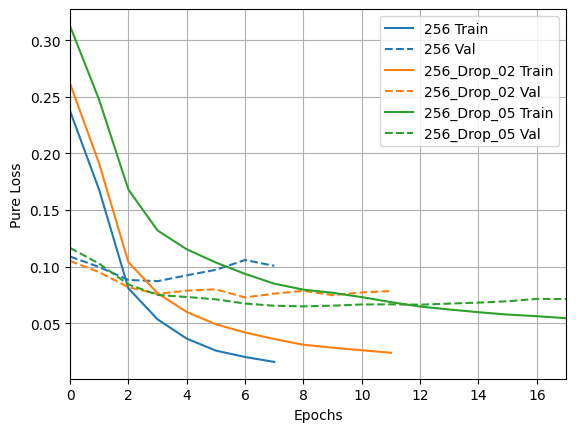

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_drop_05 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1),
]

model_256_drop_05.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_drop_05 = model_256_drop_05.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

histories['256_drop_05'] = histories_256_drop_05

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

Epoch 1/200
1688/1688 - 9s - 5ms/step - accuracy: 0.9331 - loss: 0.2254 - pure_loss: 0.2253 - val_accuracy: 0.9745 - val_loss: 0.0962 - val_pure_loss: 0.0960
Epoch 2/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9709 - loss: 0.1034 - pure_loss: 0.1034 - val_accuracy: 0.9773 - val_loss: 0.0821 - val_pure_loss: 0.0819
Epoch 3/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9822 - loss: 0.0663 - pure_loss: 0.0663 - val_accuracy: 0.9767 - val_loss: 0.0834 - val_pure_loss: 0.0831
Epoch 4/200
1688/1688 - 5s - 3ms/step - accuracy: 0.9897 - loss: 0.0423 - pure_loss: 0.0423 - val_accuracy: 0.9773 - val_loss: 0.0833 - val_pure_loss: 0.0831
Epoch 5/200
1688/1688 - 4s - 3ms/step - accuracy: 0.9941 - loss: 0.0269 - pure_loss: 0.0269 - val_accuracy: 0.9768 - val_loss: 0.0854 - val_pure_loss: 0.0852
Epoch 6/200
1688/1688 - 6s - 4ms/step - accuracy: 0.9953 - loss: 0.0197 - pure_loss: 0.0197 - val_accuracy: 0.9783 - val_loss: 0.0863 - val_pure_loss: 0.0860
Epoch 7/200
1688/1688 - 4s - 3ms/step - accuracy: 0.

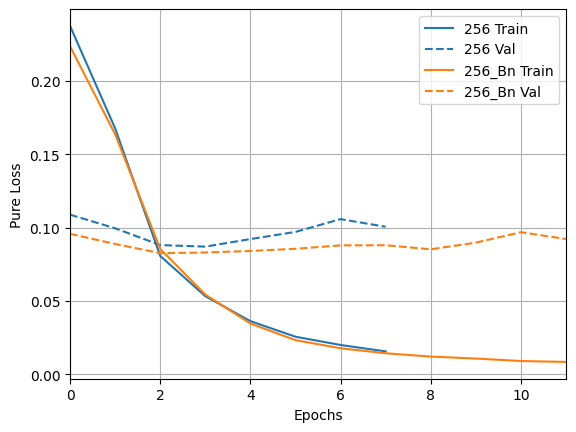

In [ ]:
histories = {}
histories['256'] = histories_256

tf.keras.backend.clear_session()
tf.random.set_seed(GLOBAL_SEED)

model_256_bn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1),
]

model_256_bn.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy",
                       tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)])

histories_256_bn = model_256_bn.fit(
    x_train, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2
)

histories['256_bn'] = histories_256_bn

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)

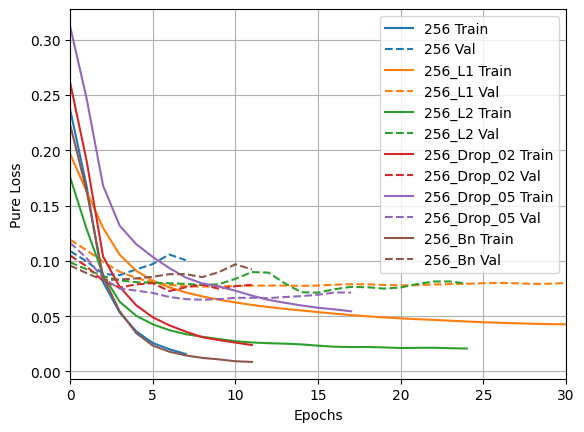

In [ ]:
histories = {}
histories['256'] = histories_256
histories['256_l1'] = histories_256_l1
histories['256_l2'] = histories_256_l2
histories['256_drop_02'] = histories_256_drop_02
histories['256_drop_05'] = histories_256_drop_05
histories['256_bn'] = histories_256_bn

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)



In [ ]:
import itertools

histories_comb_all = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    'none': None,
    'l1': tf.keras.regularizers.l1(0.0001),
    'l2': tf.keras.regularizers.l2(0.0001),
    'l1_l2': tf.keras.regularizers.l1_l2(l1=0.0001, l2=0.0001)
}

drop_options = {
    'none': 0.0,
    'drop_02': 0.2,
    'drop_05': 0.5
}

bn_options = {
    'none': False,
    'bn': True
}

# Generujemy wszystkie 24 kombinacje
combinations = list(itertools.product(reg_options.items(), drop_options.items(), bn_options.items()))

print(f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modeli...")

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    tf.keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budujemy czytelną i unikalną nazwę dla słownika historii
    # Jeśli technika jest wyłączona ('none'), pomijamy ją w sufixie, żeby nazwy były zwięzłe
    suffix_parts = []
    if reg_name != 'none': suffix_parts.append(reg_name)
    if drop_name != 'none': suffix_parts.append(drop_name)
    if bn_name != 'none': suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"256_deep{suffix}"

    # 1. Definiowanie warstw sieci dynamicznie w zależności od kombinacji
    layers = [tf.keras.layers.Input(shape=(784,))]
    hidden_units = [256, 128, 64, 16]

    for units in hidden_units:
        # Gęsta warstwa (z biasem lub bez, w zależności od Batch Normalization)
        layers.append(tf.keras.layers.Dense(
            units,
            use_bias=not bn_val,
            kernel_regularizer=reg_val
        ))

        # Opcjonalna warstwa Batch Normalization przed aktywacją
        if bn_val:
            layers.append(tf.keras.layers.BatchNormalization())

        # Aktywacja
        layers.append(tf.keras.layers.Activation("relu"))

        # Opcjonalna warstwa Dropout po aktywacji
        if drop_val > 0.0:
            layers.append(tf.keras.layers.Dropout(drop_val))

    # Warstwa wyjściowa
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))

    # Tworzenie modelu o nazwie zgodnej z Twoim formatem
    # Dynamicznie nadajemy nazwę zmiennej w przestrzeni lokalnej (opcjonalnie, dla porządku)
    model_name = f"model_256_deep{suffix}"
    model = tf.keras.Sequential(layers, name=model_name)

    # 2. Kompilacja i ustawienie specyficznego patience dla Dropout 0.2 (zgodnie z Twoim scenariuszem)
    patience_val = 5 if drop_name == 'drop_02' else 10
    callbacks = [EarlyStopping(monitor="val_pure_loss", patience=patience_val, restore_best_weights=True, verbose=0)]

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)]
    )

    # 3. Trening modelu
    print(f"Trenowanie modelu: {model_name} (patience={patience_val})...")
    history = model.fit(
        x_train, y_train,
        epochs=200,
        batch_size=32,
        validation_split=0.1,
        callbacks=callbacks,
        verbose=0 # ustawione na 0 przy 24 modelach, żeby nie zasypać konsoli tysiącami linii logów
    )

    # Zapisanie do słownika struktur
    histories_comb_all[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modeli...
Trenowanie modelu: model_256_deep (patience=10)...
Trenowanie modelu: model_256_deep_bn (patience=10)...
Trenowanie modelu: model_256_deep_drop_02 (patience=5)...
Trenowanie modelu: model_256_deep_drop_02_bn (patience=5)...
Trenowanie modelu: model_256_deep_drop_05 (patience=10)...
Trenowanie modelu: model_256_deep_drop_05_bn (patience=10)...
Trenowanie modelu: model_256_deep_l1 (patience=10)...
Trenowanie modelu: model_256_deep_l1_bn (patience=10)...
Trenowanie modelu: model_256_deep_l1_drop_02 (patience=5)...
Trenowanie modelu: model_256_deep_l1_drop_02_bn (patience=5)...
Trenowanie modelu: model_256_deep_l1_drop_05 (patience=10)...
Trenowanie modelu: model_256_deep_l1_drop_05_bn (patience=10)...
Trenowanie modelu: model_256_deep_l2 (patience=10)...
Trenowanie modelu: model_256_deep_l2_bn (patience=10)...
Trenowanie modelu: model_256_deep_l2_drop_02 (patience=5)...
Trenowanie modelu: model_256_deep_l2_drop_02_bn (patience=5)...
T

| Model Name                |   Best Epoch |   Train Loss |   Val Pure Loss |   Train Accuracy |   Val Accuracy |
|:--------------------------|-------------:|-------------:|----------------:|-----------------:|---------------:|
| 256_deep_l2_drop_02_bn    |           11 |    0.157319  |       0.0642813 |         0.957482 |       0.9825   |
| 256_deep_drop_02_bn       |           10 |    0.124267  |       0.0668226 |         0.966667 |       0.985    |
| 256_deep_drop_02          |           17 |    0.0632223 |       0.0723053 |         0.983204 |       0.9845   |
| 256_deep_l1_drop_02_bn    |           15 |    0.212971  |       0.0731659 |         0.942111 |       0.98     |
| 256_deep_l1_l2_drop_02_bn |           15 |    0.232794  |       0.0740435 |         0.93687  |       0.9795   |
| 256_deep_l2_drop_02       |           13 |    0.109032  |       0.0742089 |         0.972333 |       0.980667 |
| 256_deep_bn               |            6 |    0.0337033 |       0.0742333 |         0.

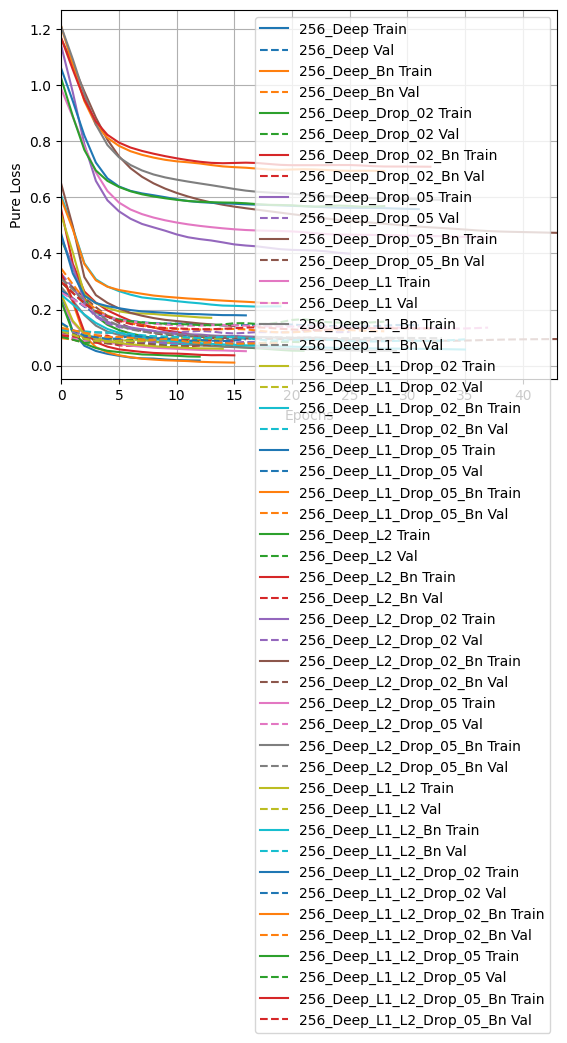

In [ ]:
# 1. Generowanie wykresu porównawczego
plotter = tfdocs.plots.HistoryPlotter(metric='pure_loss', smoothing_std=10)
# Ze względu na dużą liczbę linii (24), wykres może być gęsty, ale pokaże ogólne trendy
plotter.plot(histories_comb_all)

# 2. Generowanie tabeli zbiorczej posortowanej od najlepszego wyniku walidacji
records_comb = []
for name, history in histories_comb_all.items():
    best_epoch_idx = history.history['val_pure_loss'].index(min(history.history['val_pure_loss']))

    records_comb.append({
        "Model Name": name,
        "Best Epoch": best_epoch_idx + 1,
        "Train Loss": history.history['pure_loss'][best_epoch_idx],
        "Val Pure Loss": history.history['val_pure_loss'][best_epoch_idx],
        "Train Accuracy": history.history['accuracy'][best_epoch_idx],
        "Val Accuracy": history.history['val_accuracy'][best_epoch_idx]
    })

df_results_comb = pd.DataFrame(records_comb)
# Sortujemy po najniższym Val Pure Loss, aby od razu widzieć zwycięskie kombinacje
df_results_comb = df_results_comb.sort_values(by="Val Pure Loss", ascending=True)

print(df_results_comb.to_markdown(index=False))

In [ ]:
histories_2048_comb = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    'none': None,
    'l1': tf.keras.regularizers.l1(0.0001),
    'l2': tf.keras.regularizers.l2(0.0001),
    'l1_l2': tf.keras.regularizers.l1_l2(l1=0.0001, l2=0.0001)
}

drop_options = {
    'none': 0.0,
    'drop_02': 0.2,
    'drop_05': 0.5
}

bn_options = {
    'none': False,
    'bn': True
}

# Generujemy wszystkie 24 kombinacje
combinations = list(itertools.product(reg_options.items(), drop_options.items(), bn_options.items()))

print(f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modelu 2048...")

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    tf.keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budujemy unikalny klucz dla słownika historii (np. '2048_deep_l1_drop_02_bn')
    suffix_parts = []
    if reg_name != 'none': suffix_parts.append(reg_name)
    if drop_name != 'none': suffix_parts.append(drop_name)
    if bn_name != 'none': suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"2048_deep{suffix}"

    # 1. Definiowanie warstw sieci o architekturze 2048 -> 512 -> 128 -> 32
    layers = [tf.keras.layers.Input(shape=(784,))]
    hidden_units = [2048, 512, 128, 32]

    for units in hidden_units:
        # Gęsta warstwa (wyłączamy bias, jeśli zaraz po niej idzie Batch Normalization)
        layers.append(tf.keras.layers.Dense(
            units,
            use_bias=not bn_val,
            kernel_regularizer=reg_val
        ))

        # Batch Normalization (opcjonalnie, przed aktywacją)
        if bn_val:
            layers.append(tf.keras.layers.BatchNormalization())

        # Aktywacja nieliniowa
        layers.append(tf.keras.layers.Activation("relu"))

        # Dropout (opcjonalnie, po aktywacji)
        if drop_val > 0.0:
            layers.append(tf.keras.layers.Dropout(drop_val))

    # Warstwa wyjściowa
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))

    # Tworzenie instancji modelu o pełnej nazwie
    model_name = f"model_2048_deep{suffix}"
    model = tf.keras.Sequential(layers, name=model_name)

    # 2. Kompilacja — patience ustawione na stałe na 10 dla wszystkich modeli
    callbacks = [EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=0)]

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)]
    )

    # 3. Trening modelu
    print(f"Trenowanie modelu: {model_name} (patience=10)...")
    history = model.fit(
        x_train, y_train,
        epochs=200,
        batch_size=32,
        validation_split=0.1,
        callbacks=callbacks,
        verbose=0  # Wyciszenie logów epok, aby zachować czytelność konsoli
    )

    # Zapis historii do słownika zbiorczego
    histories_2048_comb[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modelu 2048...
Trenowanie modelu: model_2048_deep (patience=10)...
Trenowanie modelu: model_2048_deep_bn (patience=10)...
Trenowanie modelu: model_2048_deep_drop_02 (patience=10)...
Trenowanie modelu: model_2048_deep_drop_02_bn (patience=10)...
Trenowanie modelu: model_2048_deep_drop_05 (patience=10)...
Trenowanie modelu: model_2048_deep_drop_05_bn (patience=10)...
Trenowanie modelu: model_2048_deep_l1 (patience=10)...
Trenowanie modelu: model_2048_deep_l1_bn (patience=10)...
Trenowanie modelu: model_2048_deep_l1_drop_02 (patience=10)...
Trenowanie modelu: model_2048_deep_l1_drop_02_bn (patience=10)...
Trenowanie modelu: model_2048_deep_l1_drop_05 (patience=10)...
Trenowanie modelu: model_2048_deep_l1_drop_05_bn (patience=10)...
Trenowanie modelu: model_2048_deep_l2 (patience=10)...
Trenowanie modelu: model_2048_deep_l2_bn (patience=10)...
Trenowanie modelu: model_2048_deep_l2_drop_02 (patience=10)...
Trenowanie modelu: model_2048_deep_l2_dr

| Model Name                 |   Best Epoch |   Train Loss |   Val Pure Loss |   Train Accuracy |   Val Accuracy |
|:---------------------------|-------------:|-------------:|----------------:|-----------------:|---------------:|
| 2048_deep_drop_05_bn       |            9 |    0.193325  |       0.0636151 |         0.9495   |       0.984    |
| 2048_deep_l2_drop_02_bn    |           24 |    0.0955073 |       0.0642083 |         0.971648 |       0.982167 |
| 2048_deep_l2_drop_02       |           22 |    0.0778272 |       0.0652812 |         0.977963 |       0.983167 |
| 2048_deep_drop_02_bn       |           11 |    0.0363964 |       0.0658025 |         0.988741 |       0.984833 |
| 2048_deep_l1_drop_02       |           33 |    0.128999  |       0.0660632 |         0.964926 |       0.983    |
| 2048_deep_l2_drop_05_bn    |           40 |    0.258865  |       0.0667811 |         0.932389 |       0.980167 |
| 2048_deep_bn               |            6 |    0.0289508 |       0.0672562 |  

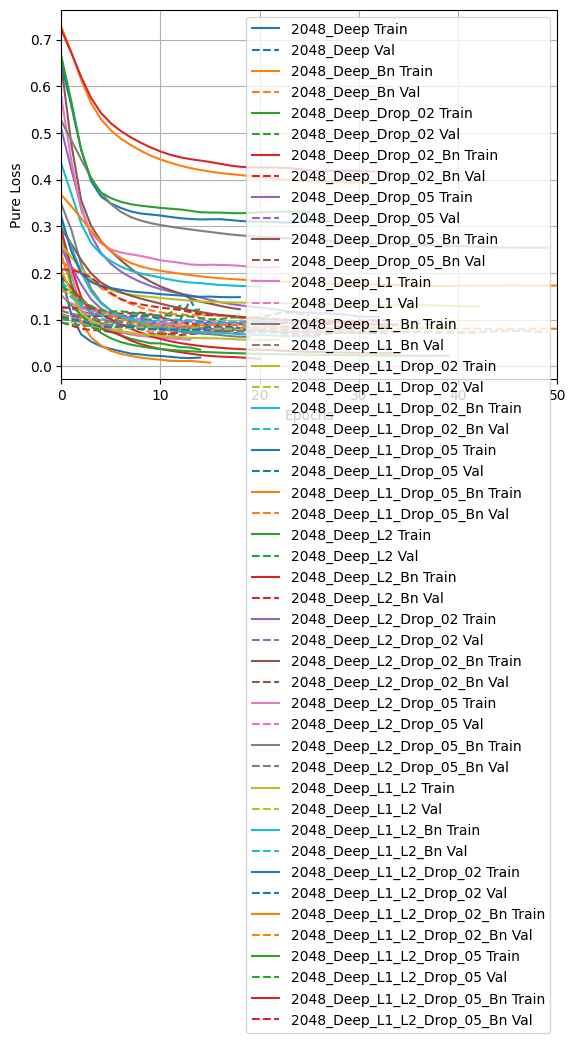

In [ ]:
# 1. Wykres zbiorczy historii zmian pure_loss
plotter = tfdocs.plots.HistoryPlotter(metric='pure_loss', smoothing_std=10)
plotter.plot(histories_2048_comb)

# 2. Tworzenie i formatowanie tabeli wynikowej za pomocą pandas
records_2048_comb = []
for name, history in histories_2048_comb.items():
    # Znajdujemy indeks epoki o najniższej stracie walidacyjnej (czyli moment, do którego cofnął nas callback)
    best_epoch_idx = history.history['val_pure_loss'].index(min(history.history['val_pure_loss']))

    records_2048_comb.append({
        "Model Name": name,
        "Best Epoch": best_epoch_idx + 1,
        "Train Loss": history.history['pure_loss'][best_epoch_idx],
        "Val Pure Loss": history.history['val_pure_loss'][best_epoch_idx],
        "Train Accuracy": history.history['accuracy'][best_epoch_idx],
        "Val Accuracy": history.history['val_accuracy'][best_epoch_idx]
    })

df_results_2048_comb = pd.DataFrame(records_2048_comb)

# Sortujemy tabelę automatycznie po najniższym 'Val Pure Loss', wskazując najbardziej efektywne konfiguracje
df_results_2048_comb = df_results_2048_comb.sort_values(by="Val Pure Loss", ascending=True)

# Wyświetlenie pełnej tabeli w formacie Markdown
print(df_results_2048_comb.to_markdown(index=False))

In [ ]:
histories_256_comb = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    'none': None,
    'l1': tf.keras.regularizers.l1(0.0001),
    'l2': tf.keras.regularizers.l2(0.0001),
    'l1_l2': tf.keras.regularizers.l1_l2(l1=0.0001, l2=0.0001)
}

drop_options = {
    'none': 0.0,
    'drop_02': 0.2,
    'drop_05': 0.5
}

bn_options = {
    'none': False,
    'bn': True
}

# Generujemy wszystkie 24 kombinacje
combinations = list(itertools.product(reg_options.items(), drop_options.items(), bn_options.items()))

print(f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modelu 256...")

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    tf.keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budujemy unikalny klucz dla słownika historii (np. '256_l1_drop_02_bn')
    suffix_parts = []
    if reg_name != 'none': suffix_parts.append(reg_name)
    if drop_name != 'none': suffix_parts.append(drop_name)
    if bn_name != 'none': suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"256{suffix}"

    # 1. Definiowanie pojedynczej warstwy ukrytej (256 neuronów)
    layers = [tf.keras.layers.Input(shape=(784,))]

    # Gęsta warstwa (wyłączamy bias, jeśli zaraz po niej idzie Batch Normalization)
    layers.append(tf.keras.layers.Dense(
        256,
        use_bias=not bn_val,
        kernel_regularizer=reg_val
    ))

    # Batch Normalization (opcjonalnie, przed aktywacją)
    if bn_val:
        layers.append(tf.keras.layers.BatchNormalization())

    # Aktywacja nieliniowa
    layers.append(tf.keras.layers.Activation("relu"))

    # Dropout (opcjonalnie, po aktywacji)
    if drop_val > 0.0:
        layers.append(tf.keras.layers.Dropout(drop_val))

    # Warstwa wyjściowa
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))

    # Tworzenie instancji modelu o pełnej nazwie zgodnie z formatem
    model_name = f"model_256{suffix}"
    model = tf.keras.Sequential(layers, name=model_name)

    # 2. Kompilacja — patience ustawione na stałe na 10 dla wszystkich modeli
    callbacks = [EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=0)]

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", tf.keras.losses.SparseCategoricalCrossentropy(name="pure_loss", from_logits=False)]
    )

    # 3. Trening modelu
    print(f"Trenowanie modelu: {model_name} (patience=10)...")
    history = model.fit(
        x_train, y_train,
        epochs=200,
        batch_size=32,
        validation_split=0.1,
        callbacks=callbacks,
        verbose=0  # Wyciszenie logów epok w celu zachowania czytelności konsoli
    )

    # Zapis historii do słownika zbiorczego
    histories_256_comb[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modelu 256...
Trenowanie modelu: model_256 (patience=10)...
Trenowanie modelu: model_256_bn (patience=10)...
Trenowanie modelu: model_256_drop_02 (patience=10)...
Trenowanie modelu: model_256_drop_02_bn (patience=10)...
Trenowanie modelu: model_256_drop_05 (patience=10)...
Trenowanie modelu: model_256_drop_05_bn (patience=10)...
Trenowanie modelu: model_256_l1 (patience=10)...
Trenowanie modelu: model_256_l1_bn (patience=10)...
Trenowanie modelu: model_256_l1_drop_02 (patience=10)...
Trenowanie modelu: model_256_l1_drop_02_bn (patience=10)...
Trenowanie modelu: model_256_l1_drop_05 (patience=10)...
Trenowanie modelu: model_256_l1_drop_05_bn (patience=10)...
Trenowanie modelu: model_256_l2 (patience=10)...
Trenowanie modelu: model_256_l2_bn (patience=10)...
Trenowanie modelu: model_256_l2_drop_02 (patience=10)...
Trenowanie modelu: model_256_l2_drop_02_bn (patience=10)...
Trenowanie modelu: model_256_l2_drop_05 (patience=10)...
Trenowanie mod

| Model Name           |   Best Epoch |   Train Loss |   Val Pure Loss |   Train Accuracy |   Val Accuracy |
|:---------------------|-------------:|-------------:|----------------:|-----------------:|---------------:|
| 256_l2_drop_05       |           17 |    0.0936904 |       0.0562929 |         0.970056 |       0.984667 |
| 256_l2_drop_05_bn    |           36 |    0.0940481 |       0.0584581 |         0.969481 |       0.9845   |
| 256_l1_drop_02       |           35 |    0.08417   |       0.0621022 |         0.973074 |       0.982167 |
| 256_l2_drop_02       |           11 |    0.0517397 |       0.0635312 |         0.983148 |       0.982333 |
| 256_drop_05          |           10 |    0.0743441 |       0.063844  |         0.976167 |       0.982    |
| 256_l1_l2_drop_02    |           14 |    0.099559  |       0.0651598 |         0.969389 |       0.981667 |
| 256_l2_drop_02_bn    |           18 |    0.0497172 |       0.0660681 |         0.983074 |       0.983167 |
| 256_drop_05_bn   

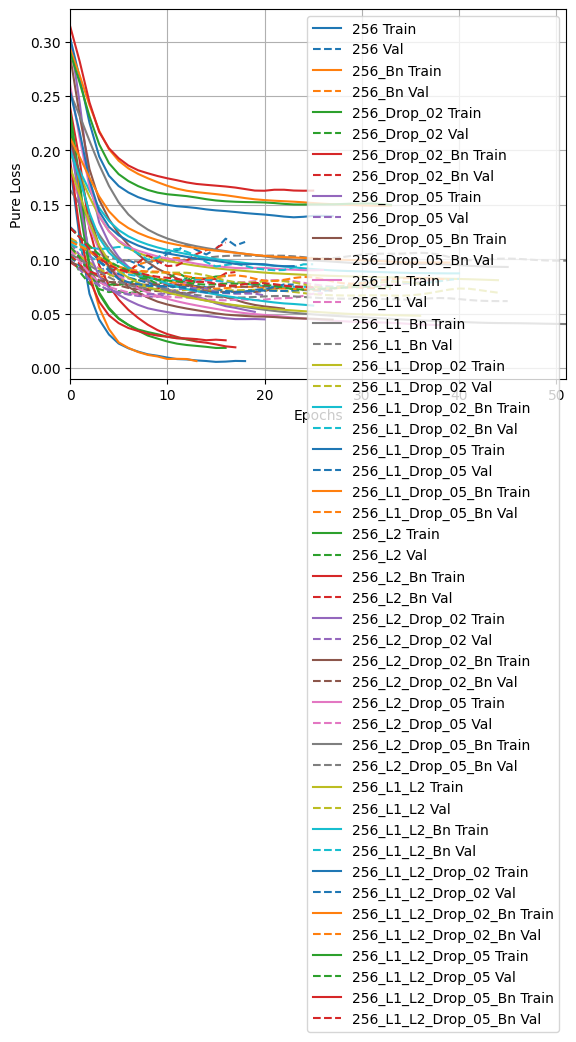

In [ ]:
# 1. Wykres zbiorczy historii zmian pure_loss
plotter = tfdocs.plots.HistoryPlotter(metric='pure_loss', smoothing_std=10)
plotter.plot(histories_256_comb)

# 2. Tworzenie i formatowanie tabeli wynikowej za pomocą pandas
records_256_comb = []
for name, history in histories_256_comb.items():
    # Znajdujemy indeks epoki o najniższej stracie walidacyjnej
    best_epoch_idx = history.history['val_pure_loss'].index(min(history.history['val_pure_loss']))

    records_256_comb.append({
        "Model Name": name,
        "Best Epoch": best_epoch_idx + 1,
        "Train Loss": history.history['pure_loss'][best_epoch_idx],
        "Val Pure Loss": history.history['val_pure_loss'][best_epoch_idx],
        "Train Accuracy": history.history['accuracy'][best_epoch_idx],
        "Val Accuracy": history.history['val_accuracy'][best_epoch_idx]
    })

df_results_256_comb = pd.DataFrame(records_256_comb)

# Sortujemy tabelę automatycznie po najniższym 'Val Pure Loss'
df_results_256_comb = df_results_256_comb.sort_values(by="Val Pure Loss", ascending=True)

# Wyświetlenie pełnej tabeli w formacie Markdown
print(df_results_256_comb.to_markdown(index=False))